# Spatial Domains with BANKSY

Leiden clustering on a transcriptomic PCA assigns labels based solely on each cell's own expression vector: two cells receive the same label because their genes look alike, regardless of whether they occupy the same neighborhood or opposite ends of the tissue. This is appropriate for *cell typing*.

For *tissue domain* segmentation, a cell at a domain boundary should carry signal from its surroundings, not just its own transcriptome. [BANKSY](https://www.nature.com/articles/s41588-024-01664-3) (Singhal et al., *Nature Genetics* 2024) concatenates a neighborhood-averaged feature vector onto each cell's expression before PCA/clustering: spatial context is baked into the input rather than evaluated post-hoc.

This notebook builds the BANKSY pipeline step by step, then introduces `tl.banksy_sweep` as the shortcut for scanning multiple parameter combinations. Setup follows the same steps as every other notebook: load, QC/filter, normalize, log-transform.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import scanpy as sc
import astrolabe as ab

In [2]:
mdata = ab.datasets.xenium()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


...

INFO:astrolabe.tl._graph:spatial_neighbors: 154469 cells, 891792 edges (mean degree 5.8) [generic]


INFO:astrolabe.pp._qc:filter_isolated: removing 199 / 154469 cells (neighbors_key='spatial_neighbors', max_neighbor=60 um, min_neighbor=50 um)


INFO:astrolabe.pipeline:  [filter_isolation] 154469 → 154270 cells  (removed 199, 0.1%)


INFO:astrolabe.pipeline:filter_cells: done — 154270 cells × 377 genes


INFO:astrolabe.pipeline:filter_xenium: done — 154270 cells × 377 genes


## 1. The baseline: expression-only Leiden

The standard pipeline from notebook 01: PCA on HVG expression, transcriptomic KNN graph, Leiden. This result is preserved as `leiden` for comparison against BANKSY's spatial domains later.

In [3]:
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)
ab.tl.pca(mdata)
sc.pp.neighbors(mdata['xenium'])  # transcriptomic graph -> uns['neighbors']
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors', key_added='leiden')

mdata['xenium'].obs['leiden'].value_counts()

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pp\_normalize.py:281: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return sc.pp.highly_variable_genes(


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\tl\_cluster.py:90: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 9 clusters


leiden
0    38864
1    35555
2    21005
3    19520
4    17241
5    12347
6     7478
7     1181
8     1079
Name: count, dtype: int64

## 2. Building the BANKSY feature matrix

`pp.banksy_matrix` reads `obsp['{neighbors_key}_connectivities']` to identify each cell's spatial neighbors, so `tl.spatial_neighbors` must run first. This overwrites `uns['neighbors']` with the spatial graph: the same ordering constraint as notebook 01, which is why expression-based clustering ran first above.

For each cell, `banksy_matrix` computes **M0** (mean neighbor expression; optionally **|M1|**, an azimuthal Gabor magnitude, via `agf=True`) then concatenates a √(1−λ)-scaled copy of the cell's own expression with a √λ-scaled copy of M0. Output is in `obsm['X_banksy']` with shape `(n_cells, 2 × n_genes)`.

λ controls the self-vs-neighborhood balance:
- **λ ≈ 0.2** — predominantly self-expression with mild neighborhood smoothing. Appropriate for cell typing.
- **λ ≈ 0.8** — predominantly neighborhood. Appropriate for spatial domain segmentation, where a cell's label should reflect its surrounding tissue context.

In [4]:
ab.tl.spatial_neighbors(mdata, coord_type='delaunay', delaunay_max_dist=200)
ab.pp.banksy_matrix(mdata, lambda_param=0.8)

mdata['xenium'].obsm['X_banksy'].shape

INFO:astrolabe.tl._graph:spatial_neighbors: overwriting uns['neighbors'] (previously set by sc.pp.neighbors or a prior call). Re-run sc.pp.neighbors if you need transcriptomic neighbors downstream.


INFO:astrolabe.tl._graph:spatial_neighbors: 154270 cells, 924784 edges (mean degree 6.0) [delaunay]


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.80  agf=False  → obsm['X_banksy']  shape=(154270, 754)


(154270, 754)

## 3. PCA → graph → Leiden on the BANKSY matrix

The pipeline is identical to standard clustering — only the input representation changes:

1. `tl.pca(mdata, use_rep='X_banksy')` — PCA on the concatenated matrix (per the BANKSY paper: cluster the PCA embedding, not the raw concatenated features).
2. `sc.pp.neighbors(..., use_rep='X_pca_banksy')` — KNN graph on the BANKSY-PCA coordinates. Spatial information is already embedded via M0; this builds an ordinary graph for Leiden.
3. `tl.cluster` on that graph, written to `key_added='banksy_leiden'` so it doesn't overwrite the baseline `leiden` column.

In [5]:
ab.tl.pca(mdata, use_rep='X_banksy', key_added='X_pca_banksy')
sc.pp.neighbors(mdata['xenium'], use_rep='X_pca_banksy')
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors', key_added='banksy_leiden')

mdata['xenium'].obs['banksy_leiden'].value_counts()

INFO:astrolabe.tl._embedding:pca (use_rep='X_banksy'): 50 components → obsm['X_pca_banksy']


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\tl\_cluster.py:90: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 11 clusters


banksy_leiden
0     29569
1     29469
2     28951
3     16836
4     14119
5     12206
6      8203
7      5720
8      5383
9      2580
10     1234
Name: count, dtype: int64

## 4. Expression clusters vs. spatial domains, side by side

`pl.points(...)` returns a lazy `SpatialPanel`; `|` composes two panels side by side without rendering either first. Left: `leiden` (expression only). Right: `banksy_leiden` (λ=0.8, spatially smoothed) — same tissue, same cells.

`banksy_leiden` regions should appear more contiguous — less salt-and-pepper intermixing — since each cell's label now incorporates its neighbors' expression.

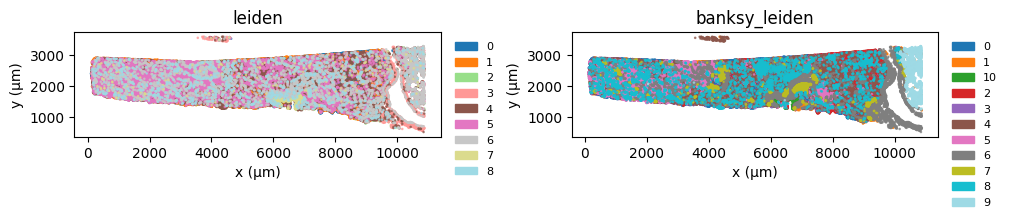

In [6]:
panel = ab.pl.points(mdata, color='leiden')  # not rendered yet
(panel | ab.pl.points(mdata, color='banksy_leiden')).show()

BANKSY (λ=0.8, res=0.5) identifies 11 domains vs. the expression-only Leiden's 9 clusters. The 2 additional clusters reflect boundary zones that expression-only clustering merged: cells sitting at the interface between two distinct tissue regions often have an intermediate expression profile (mixing transcripts from adjacent cell types) that pure expression clustering places in one cluster or the other, but BANKSY, incorporating neighborhood context, separates into its own domain. In the side-by-side tissue plot, BANKSY domains should appear with more spatially contiguous, less "salt-and-pepper" boundaries — individual cells are less likely to be assigned to a different cluster than their immediate neighbors because their neighborhood term anchors them to the local context.

`+` overlays layers on shared axes: useful here to check whether domain boundaries align with actual cell boundaries rather than cutting through them arbitrarily.

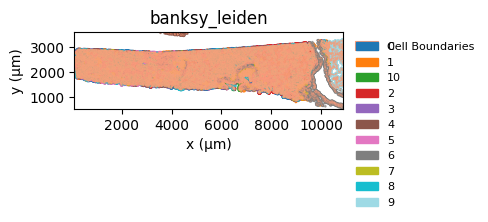

In [7]:
(ab.pl.points(mdata, color='banksy_leiden') + ab.pl.boundaries(mdata, alpha=0.3)).show()

The overlay reveals whether BANKSY domain boundaries align with physical cell boundaries or cut through them. Well-aligned transitions (where the color change in `pl.points()` coincides with a gap between adjacent cell boundary polygons) confirm that BANKSY is assigning whole cells to domains. Isolated islands of a minority color surrounded by cells of a different domain label indicate genuine boundary cells: their own expression and their neighborhood expression partially disagree, so BANKSY places them at the margin. Systematic misalignment, where a domain-color transition runs across a dense block of cells that all share similar boundary shapes, suggests the Leiden resolution is too high and is splitting a biologically uniform region into artificial sub-domains; reduce resolution or λ.

## 5. `tl.banksy_sweep`: the same pipeline, grid-searched

λ and resolution are rarely known in advance — λ trades off cell-type purity against spatial smoothness; resolution controls domain count. `tl.banksy_sweep` runs the complete sequence (`banksy_matrix` → PCA → `sc.pp.neighbors` → Leiden) for each `(λ, resolution)` combination and stores each result as a named `obs` column.

A 2×2 grid illustrates the API; a production scan typically covers a wider range.

In [8]:
summary = ab.tl.banksy_sweep(
    mdata,
    lambda_params=[0.2, 0.8],
    resolutions=[0.3, 0.5],
)
summary

INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.20  agf=False  → obsm['_banksy_tmp_0.2']  shape=(154270, 754)


INFO:astrolabe.tl._embedding:pca (use_rep='_banksy_tmp_0.2'): 30 components → obsm['X_pca']


INFO:astrolabe.tl._banksy_sweep:banksy_sweep: λ=0.20  res=0.30  → 7 clusters  ('banksy_sweep_L0.2_R0.3')


INFO:astrolabe.tl._banksy_sweep:banksy_sweep: λ=0.20  res=0.50  → 10 clusters  ('banksy_sweep_L0.2_R0.5')


INFO:astrolabe.pp._banksy:banksy_matrix: λ=0.80  agf=False  → obsm['_banksy_tmp_0.8']  shape=(154270, 754)


INFO:astrolabe.tl._embedding:pca (use_rep='_banksy_tmp_0.8'): 30 components → obsm['X_pca']


INFO:astrolabe.tl._banksy_sweep:banksy_sweep: λ=0.80  res=0.30  → 9 clusters  ('banksy_sweep_L0.8_R0.3')


INFO:astrolabe.tl._banksy_sweep:banksy_sweep: λ=0.80  res=0.50  → 11 clusters  ('banksy_sweep_L0.8_R0.5')


INFO:astrolabe.tl._banksy_sweep:banksy_sweep: done — 4 runs


,lambda,resolution,n_clusters,obs_key
0,0.2,0.3,7,banksy_sweep_L0.2_R0.3
1,0.2,0.5,10,banksy_sweep_L0.2_R0.5
2,0.8,0.3,9,banksy_sweep_L0.8_R0.3
3,0.8,0.5,11,banksy_sweep_L0.8_R0.5


The sweep reveals two things. First, λ has a larger effect on cluster count than resolution: jumping from λ=0.2 to λ=0.8 at fixed resolution=0.3 increases clusters from 7 to 9 (2 extra boundary domains), while increasing resolution from 0.3 to 0.5 at fixed λ=0.8 increases from 9 to 11. Second, the low-λ setting (0.2) gives fewer domains at both resolutions (7–10) than high-λ (9–11): the neighborhood term at λ=0.8 resolves finer spatial structure that expression-only analysis misses. For a production sweep, the "stable plateau" is the parameter region where increasing resolution no longer splits existing domains but instead creates new biologically interpretable ones; if increasing resolution only adds very small clusters with no clear marker genes, the domains are over-segmented.

Each row of the summary is one `(λ, resolution)` run, named `banksy_sweep_L{lambda}_R{resolution}` — that obs column holds its cluster labels, and `uns['banksy_sweep']` holds this table for later reference. Below, the low-λ (cell-typing-flavored) and high-λ (domain-flavored) runs at the same resolution are compared directly on the tissue.

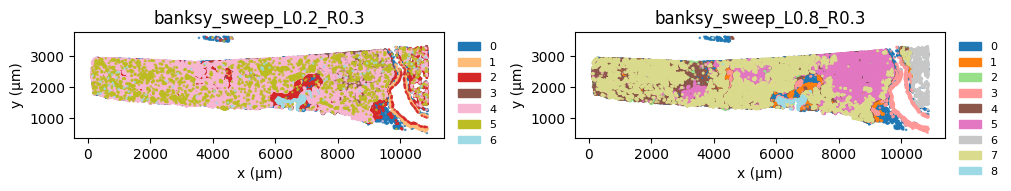

In [9]:
low_lambda_key = summary.loc[(summary['lambda'] == 0.2) & (summary['resolution'] == 0.3), 'obs_key'].item()
high_lambda_key = summary.loc[(summary['lambda'] == 0.8) & (summary['resolution'] == 0.3), 'obs_key'].item()

(ab.pl.points(mdata, color=low_lambda_key) | ab.pl.points(mdata, color=high_lambda_key)).show()

Comparing low-λ (0.2, left) and high-λ (0.8, right) at the same resolution shows what the neighborhood term adds. The low-λ map resembles expression-only Leiden: clusters follow transcriptomic identity and may appear salt-and-pepper where adjacent cells have different expression profiles. The high-λ map shows larger, more spatially contiguous patches: cells that differ slightly in expression from their neighbors are pulled toward the neighborhood consensus, reducing isolated mis-assigned cells. If the two maps look nearly identical for a given dataset, the neighborhood signal is weak: either the tissue lacks spatially structured domains and expression-only clustering is the appropriate choice, or `delaunay_max_dist` is too permissive and is blending spatially distant cells into each neighborhood average.

## Manual pipeline vs. `tl.banksy_sweep`

Build the pipeline by hand (sections 2–4) to understand exactly what BANKSY changes about the input, or when a single `(λ, resolution)` is already known. Use `tl.banksy_sweep` to scan multiple combinations and compare domain counts in `uns['banksy_sweep']`.